# A/B Testing — Analysis

A small notebook using the existing `validator.py` and `analyzer.py` modules. Place this notebook in the same folder as those modules and `test_in_50.csv`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from validator import DataValidator
from analyzer import ABAnalyzer

CSV_PATH = Path("test_in_50.csv")
assert CSV_PATH.is_file(), f"CSV not found: {CSV_PATH.resolve()}"

## 1. Validate the CSV

Invalid records and all records belonging to duplicate user IDs are excluded.

In [2]:
validator = DataValidator(str(CSV_PATH))
validator.validate()

valid_data = validator.get_valid_data()
errors = validator.get_errors()

print(f"Valid records: {len(valid_data)}")
print(f"Validation errors: {len(errors)}")
for error in errors:
    print("-", error)

Valid records: 41
Validation errors: 9
- Detected duplicate: {'user_id': 'U010', 'group': 'A', 'converted': '1'}
- Detected duplicate: {'user_id': 'U020', 'group': 'B', 'converted': '0'}
- Invalid group: {'user_id': 'U041', 'group': 'C', 'converted': '1'}
- Invalid conversion: {'user_id': 'U042', 'group': 'A', 'converted': '2'}
- Missing value: {'user_id': 'U043', 'group': 'B', 'converted': ''}
- Missing value: {'user_id': 'U044', 'group': '', 'converted': '1'}
- Missing value: {'user_id': '', 'group': 'A', 'converted': '0'}
- Detected duplicate: {'user_id': 'U010', 'group': 'B', 'converted': '1'}
- Detected duplicate: {'user_id': 'U020', 'group': 'A', 'converted': '0'}


## 2. Conversion rates

For each group, conversion rate = converted users / total users.

In [3]:
analyzer = ABAnalyzer(valid_data)

if not analyzer.A or not analyzer.B:
    raise ValueError("Both A and B must have at least one valid record.")

p_A, p_B = analyzer.conversion_rates()
print(f"A: {sum(analyzer.A)}/{len(analyzer.A)} = {p_A:.2%}")
print(f"B: {sum(analyzer.B)}/{len(analyzer.B)} = {p_B:.2%}")
print(f"Absolute lift (B - A): {(p_B - p_A):+.2%} (percentage-point difference)")

A: 10/20 = 50.00%
B: 13/21 = 61.90%
Absolute lift (B - A): +11.90% (percentage-point difference)


## 3. Two-proportion Z-test

- $H_0: p_A = p_B$
- $H_1: p_A \ne p_B$

The Z-test uses the **pooled proportion** under the null hypothesis. The normal approximation can be unreliable for small groups.

In [4]:
se = analyzer.standard_error()
if se == 0:
    raise ValueError("Standard error is zero; the Z statistic is undefined.")

alpha = 0.05
z, p_value = analyzer.z_test()
print(f"Pooled proportion: {analyzer.pool_prop():.4f}")
print(f"Standard error: {se:.4f}")
print(f"Z statistic: {z:.4f}")
print(f"Two-sided p-value: {p_value:.4f}")
print(f"Conclusion (alpha={alpha}): {analyzer.interpret(alpha)}")

Pooled proportion: 0.5610
Standard error: 0.1551
Z statistic: 0.7678
Two-sided p-value: 0.4426
Conclusion (alpha=0.05): Fail to reject H0. No statistically significant difference between A and B.


## 4. Visualization (optional)

Compare the observed conversion rates. These bars are descriptive, not confidence intervals.

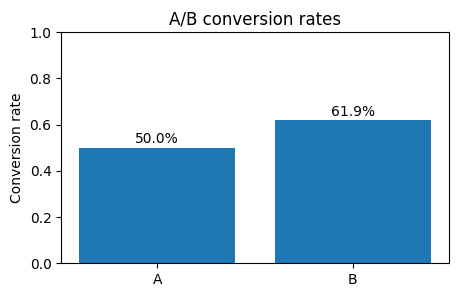

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["A", "B"], [p_A, p_B])
ax.set_ylim(0, 1)
ax.set_ylabel("Conversion rate")
ax.set_title("A/B conversion rates")
for i, rate in enumerate([p_A, p_B]):
    ax.text(i, rate + 0.02, f"{rate:.1%}", ha="center")
plt.show()

**Note:** This 50-row CSV is a software test fixture, not a large-sample experiment. Interpret its Z-test cautiously; lack of significance does not establish equivalence.